# M06-1 | Minimal QAT: the Prepared QAT Graph Is an Ordinary GraphModule, Train It Directly

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m06_qat_pipeline/01_qat_minimal.ipynb)

We saw what a QAT graph looks like in M04-2 (the conv + BN QAT subgraph, where the fake quants go). This chapter is only about **training**.
This notebook answers three things: can the prepared graph do backward, what the training loop needs to do extra, and whether the graph after convert is the same as PTQ's.

- **A.** STE: the round inside fake quant has no gradient, so what happens in backward.
- **B.** The minimal training loop: `export(train=True)` → `prepare_qat_pt2e` → switch train/eval every epoch → train.
- **C.** convert: the graph has the same shape as PTQ's; accuracy and test loss of fp32, PTQ, and QAT.

Why STE is necessary and how it is derived: see the blog post
[Understanding Fake Quantization in Quantization Aware Training](https://bobondemon.github.io/2022/11/19/%E6%90%9E%E6%87%82-Quantization-Aware-Training-%E4%B8%AD%E7%9A%84-Fake-Quantization/#Fake-quantization-%E5%BF%85%E9%A0%88%E8%A6%81%E8%83%BD%E5%BE%AE%E5%88%86) (in Chinese).

In [1]:
#| include: false
# When running on Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m06_qat_pipeline")

In [2]:
import copy

import matplotlib.pyplot as plt
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats

from common.data import calibration_batches, evaluate, evaluate_loss, make_loader, trained_tiny_net
from common.graph_utils import op_counts, qdq_nodes
from common.models import example_inputs
from common.pt2e import (
    FakeQuantize,
    MovingAverageMinMaxObserver,
    convert_pt2e,
    disable_observer,
    export_module,
    get_xnnpack_quantizer,
    move_exported_model_to_eval,
    move_exported_model_to_train,
    prepare_pt2e,
    prepare_qat_pt2e,
    quiet,
)
from common.qat import qat_quantizer
from common.viz import table

quiet()
_ = torch.manual_seed(0)
set_matplotlib_formats("svg")
BLUE, MUTED = "#2a78d6", "#52514e"

## A. STE: the Gradient of Fake Quant

Take an int8 `FakeQuantize`, calibrate it with data in [-1, 1], then `disable_observer` to freeze the range (M02-2), and look at the output and gradient at each point:

In [3]:
fq = FakeQuantize(observer=MovingAverageMinMaxObserver, dtype=torch.int8, qscheme=torch.per_tensor_affine,
                  quant_min=-128, quant_max=127, eps=2**-12)
with torch.no_grad():
    fq(torch.linspace(-1, 1, 100))
fq.apply(disable_observer)  # freeze the range; later inputs no longer change scale

scale, zp = fq.calculate_qparams()
lo, hi = (fq.quant_min - int(zp)) * float(scale), (fq.quant_max - int(zp)) * float(scale)

x = torch.tensor([-3.0, -0.5, 0.0, 0.3, 0.9, 1.5, 4.0], requires_grad=True)
fq(x).sum().backward()
assert x.grad is not None
table([[f"{float(xi):+.1f}", f"{float(yi):+.4f}", f"{float(gi):.0f}", "inside" if lo <= xi <= hi else "outside"]
       for xi, yi, gi in zip(x, fq(x), x.grad)],
      ["x", "fq(x)", "dfq/dx", f"Inside range [{lo:.2f}, {hi:.2f}]?"])

x,fq(x),dfq/dx,"Inside range [-1.00, 1.00]?"
-3.0,-0.9961,0,outside
-0.5,-0.5020,1,inside
+0.0,+0.0000,1,inside
+0.3,+0.2980,1,inside
+0.9,+0.9020,1,inside
+1.5,+1.0039,0,outside
+4.0,+1.0039,0,outside


In [4]:
inside = (x >= lo) & (x <= hi)
assert torch.equal(x.grad, inside.float())  # gradient 1 inside the range, 0 outside

Sweep x over an interval and plot the forward output and the backward gradient:

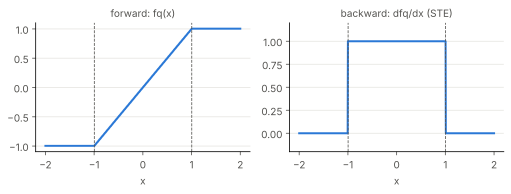

In [5]:
#| code-fold: true
#| code-summary: Plotting code
xs = torch.linspace(-2, 2, 801, requires_grad=True)
ys = fq(xs)
ys.sum().backward()
assert xs.grad is not None
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.2, 2.8))
ax1.plot(xs.detach(), ys.detach(), color=BLUE, lw=2)
ax1.set_title("forward: fq(x)", color=MUTED, fontsize=10)
ax2.plot(xs.detach(), xs.grad, color=BLUE, lw=2)
ax2.set_title("backward: dfq/dx (STE)", color=MUTED, fontsize=10)
ax2.set_ylim(-0.2, 1.2)
for ax in (ax1, ax2):
    for edge in (lo, hi):
        ax.axvline(edge, color=MUTED, lw=0.8, ls="--")
    ax.set_xlabel("x", color=MUTED)
    ax.grid(axis="y", color="#e6e5e1", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
fig.tight_layout()
plt.show()

The dashed lines are the two ends of the range.

- Forward really does round and clamp: the output lands on the grid of scale, and values outside the range are clamped to the boundary. The int8 grid is fine, so the left plot looks almost like a straight line.
- Backward treats round as the identity function: gradient 1 inside the range, 0 outside. This is STE (straight-through estimator).
- Values outside the range get gradient 0, so this step gives them no update. So estimating the range too small is not just an accuracy issue; it also makes some values stop learning (an inference; no separate experiment here).

STE is what makes QAT trainable. The next section takes the graph from `prepare_qat_pt2e` and runs backward on it directly.

## B. The Minimal Training Loop

QAT must export in train mode (`export_module(..., train=True)`, so that BN is the train version of the op, M00-2).
`qat_quantizer(bits=8)` is this project's tool (`common/qat.py`): XNNPACKQuantizer's QAT config (per-channel weight), with only the weight's fake quant swapped for the non-fused version; the reason is in M06-3. For now just know that it returns a Quantizer.

In [6]:
model = trained_tiny_net()
test_loader = make_loader(n=1024, seed=2, shuffle=False)

gm = export_module(copy.deepcopy(model), example_inputs(), train=True)
prepared = prepare_qat_pt2e(gm, qat_quantizer(bits=8))

params = dict(prepared.named_parameters())
fq_names = [n.target for n in prepared.graph.nodes if n.op == "call_module" and "activation_post_process" in n.target]
fq_params = sum(p.numel() for n in fq_names for p in prepared.get_submodule(n).parameters())
print(f"Parameters of the prepared graph: {len(params)} tensors, e.g. {list(params)[:3]}")
print(f"{len(fq_names)} fake quant modules, number of parameters in them: {fq_params}")
assert fq_params == 0 and all(not n.startswith("activation_post_process") for n in params)

Parameters of the prepared graph: 14 tensors, e.g. ['stem.conv.weight', 'stem.bn.weight', 'stem.bn.bias']
16 fake quant modules, number of parameters in them: 0


The parameters of the prepared graph are just those of the original model's conv, BN, and fc; fake quant has only buffers (min/max/scale) and no parameters, so the optimizer never touches scale (`LearnableFakeQuantize` in M06-5 does).

The training loop differs from an ordinary PyTorch loop by only two lines: the exported graph has no `.train()`/`.eval()` semantics (M00-2), BN's `training` is written in the node's arguments, so use `move_exported_model_to_train`/`move_exported_model_to_eval` to edit the graph.

In [7]:
def train_qat_minimal(prepared, epochs=3, lr=1e-3):
    """Minimal QAT loop: switch to train at the start of each epoch and to eval at the end. Returns (train loss, test loss) per epoch."""
    loader = make_loader(n=1024, seed=1)
    opt = torch.optim.SGD(prepared.parameters(), lr=lr, momentum=0.9)
    lossf = torch.nn.CrossEntropyLoss()
    history, loss = [], torch.zeros(())
    for _ in range(epochs):
        move_exported_model_to_train(prepared)  # BN uses batch statistics
        for xb, yb in loader:
            opt.zero_grad()
            loss = lossf(prepared(xb), yb)
            loss.backward()  # fake quant goes through STE; gradients reach conv/fc weights as usual
            opt.step()
        move_exported_model_to_eval(prepared)  # BN uses running stats during evaluation
        history.append((float(loss), evaluate_loss(prepared, test_loader)))
    return history


history = train_qat_minimal(prepared)
table([[ep, f"{tr:.4f}", f"{te:.4f}"] for ep, (tr, te) in enumerate(history)],
      ["epoch", "train loss of the last batch", "test loss (eval mode)"])

epoch,train loss of the last batch,test loss (eval mode)
0,0.0111,0.8279
1,0.0072,0.8266
2,0.0052,0.8231


- The prepared QAT graph is an ordinary GraphModule: the optimizer takes `prepared.parameters()` and `loss.backward()` works as usual.
- lr is 1e-3, one tenth of fp32 training (1e-2): QAT is fine-tuning, and the starting point is already a trained model.
- The test loss here is computed while the observers are still on; before evaluation you actually need to turn the observers off too, and M06-2 explains why.

Later notebooks use `train_qat()` from `common/qat.py` instead. The loop body is the same, plus a hook called at every step (M06-5 uses it to turn on range learning midway).

## C. convert: Compared with the PTQ Graph, and Accuracy

Before evaluation and convert, `disable_observer` first (M06-2). There are two control groups:

- **PTQ int8**: the same model through M05's PTQ.
- **fp32 retrained for 3 epochs**: the same loop without inserting fake quant, directly training the exported train graph.

In [8]:
prepared.apply(disable_observer)
qat_int8 = convert_pt2e(copy.deepcopy(prepared))

ptq_prepared = prepare_pt2e(export_module(copy.deepcopy(model), example_inputs()), get_xnnpack_quantizer(is_per_channel=True)[0])
with torch.no_grad():
    for batch in calibration_batches(128):
        ptq_prepared(*batch)
ptq_int8 = convert_pt2e(ptq_prepared)

retrained = export_module(copy.deepcopy(model), example_inputs(), train=True)
_ = train_qat_minimal(retrained)

c_qat, c_ptq = op_counts(qat_int8), op_counts(ptq_int8)
table([["batch_norm", c_ptq.get("batch_norm", 0), c_qat.get("batch_norm", 0)],
       ["conv2d", c_ptq.get("conv2d", 0), c_qat.get("conv2d", 0)],
       ["q/dq node", len(qdq_nodes(ptq_int8)), len(qdq_nodes(qat_int8))]],
      ["", "PTQ int8", "QAT int8"])

,PTQ int8,QAT int8
batch_norm,0,0
conv2d,4,4
q/dq node,28,28


In [9]:
assert c_qat == c_ptq  # identical op composition

Both paths call the same `convert_pt2e`, which has no `is_qat` argument: it first replaces observers/fake quants with q/dq, then tries to match the QAT conv + BN subgraph (the five steps of M02-3, M04-2).
In PTQ, BN was already folded at prepare time, so this step does nothing; in QAT, the subgraph match succeeds and BN is folded into conv only at this step. So the two end up with the same shape, and the backend cannot tell them apart.

Accuracy:

In [10]:
models = {"fp32": model, "fp32 retrained 3 epochs (not quantized)": retrained, "PTQ int8": ptq_int8, "QAT int8": qat_int8}
results = {name: (evaluate(m, test_loader), evaluate_loss(m, test_loader)) for name, m in models.items()}
table([[name, f"{acc:.4f}", f"{loss:.4f}"] for name, (acc, loss) in results.items()],
      ["Model", "accuracy (1024 samples)", "test loss"])

Model,accuracy (1024 samples),test loss
fp32,0.7109,0.8263
fp32 retrained 3 epochs (not quantized),0.7139,0.8270
PTQ int8,0.7051,0.8286
QAT int8,0.7119,0.8274


In [11]:
losses = [loss for _, loss in results.values()]
assert max(losses) - min(losses) < 0.01

- **The metric switches to test loss**: QAT changes the weights, and M05's "SQNR against the original fp32 output" measures "how far from the original model", not "how good after quantization". Test loss is continuous and is the quantity QAT optimizes directly.
- **The comparison target is the "retrained, not quantized" row**: QAT adds one more thing, "training". To separate the effect of training itself from that of quantization, the baseline must be the fp32 retrained with the same recipe, not the original fp32.
- **At int8 there is nothing to rescue**: the test loss of the four rows differs by less than 0.01, and a single seed cannot tell them apart. PTQ int8 is already right next to fp32.

To see the benefit of QAT you have to push the bit width down; M06-4 compares at int4. Before that, M06-2 and M06-3 get evaluation right first.

## Summary

- The round in fake quant passes gradients through STE: 1 inside the range, 0 outside.
- The QAT flow: `export(train=True)` → `prepare_qat_pt2e` → training (switch train/eval every epoch) → `disable_observer` → `convert_pt2e`.
- After convert it has the same shape as PTQ; at int8 there is no accuracy difference between QAT and PTQ.